# Smart Waste Classification Using Vision Transformers
## Evaluating Hazardous Waste Detection and Classification Reliability

**Research question:** How reliably can a Vision Transformer classify waste images into different waste categories, and what types of errors could create risks when identifying hazardous waste?

**Dataset:** [`huaweilin/waste-classification`](https://huggingface.co/datasets/huaweilin/waste-classification) (4 classes: Hazardous, Non-Recyclable, Organic, Recyclable; 18 subclasses; ~1,976 images, single split `cleaned`).

**Model:** [`google/vit-base-patch16-224`](https://huggingface.co/google/vit-base-patch16-224) (ViT-Base, patch 16, 224×224, Apache-2.0).

**Author:** **Shaikh Maha** **Student ID:** **1560980** · **Platform:** Google Colab (Tesla T4 GPU) · **Seed:** 42 · **Code:** see GitHub repository linked in the report

**Notebook structure:** 1–2 setup · 3–7 dataset loading, cleaning and splitting · 8–10 preprocessing, augmentation and model · 11–12 fine-tuning · 13–14 test evaluation and hazardous-waste error analysis · 15 image-quality robustness experiment · 16–18 example predictions and saved results.

## 1. Install required libraries

In [3]:
!pip install -q "transformers>=4.40" "datasets>=2.19" accelerate evaluate scikit-learn seaborn pillow imagehash

## 2. Import dependencies and set the random seed

In [4]:
import os, io, json, random, time, hashlib, warnings
import numpy as np
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image, ImageFilter, ImageEnhance
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix)
from datasets import load_dataset
from torchvision import transforms
import transformers
from transformers import (ViTImageProcessor, ViTForImageClassification,
                          TrainingArguments, Trainer)

warnings.filterwarnings("ignore")

SEED = 42
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
set_seed()

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("transformers:", transformers.__version__, "| torch:", torch.__version__)
print("Device:", DEVICE)
if DEVICE == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: no GPU found. Training will be very slow. Enable GPU in Runtime settings.")

# Output folders (everything the report needs is saved here)
RESULTS_DIR = "results"
FIG_DIR = os.path.join(RESULTS_DIR, "figures")
MODEL_DIR = "saved_model"
for d in (RESULTS_DIR, FIG_DIR, MODEL_DIR):
    os.makedirs(d, exist_ok=True)

# Consistent colour palette for all charts
PALETTE = {
    "forest": "#1F4D3A",   # dark forest green
    "mint":   "#9FD9B8",   # mint green
    "cream":  "#F7F3EA",   # warm off-white
    "charcoal": "#2E2E2E", # charcoal
    "orange": "#D97B29",   # restrained orange (warnings / hazardous)
}
CLASS_COLOURS = [PALETTE["orange"], PALETTE["charcoal"], PALETTE["mint"], PALETTE["forest"]]
sns.set_theme(style="whitegrid", rc={"axes.facecolor": PALETTE["cream"], "figure.facecolor": "white"})

transformers: 5.20.2 | torch: 2.11.0+cu130
Device: cuda
GPU: Tesla T4


## 3. Load the dataset from Hugging Face

In [5]:
DATASET_ID = "huaweilin/waste-classification"
raw = load_dataset(DATASET_ID, split="cleaned")
print(raw)
print("Columns:", raw.column_names)
print("Number of images:", len(raw))
print("\nFirst example (without image):", {k: v for k, v in raw[0].items() if k != "image"})

README.md:   0%|          | 0.00/2.44k [00:00<?, ?B/s]

data/cleaned-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  385MB            

data/cleaned-00000-of-00002.parquet: downloading bytes:           |  0.00B            

data/cleaned-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  408MB            

data/cleaned-00001-of-00002.parquet: downloading bytes:           |  0.00B            

Generating cleaned split:   0%|          | 0/1976 [00:00<?, ? examples/s]

Dataset({
    features: ['image', 'class', 'subclass', 'options', 'answer'],
    num_rows: 1976
})
Columns: ['image', 'class', 'subclass', 'options', 'answer']
Number of images: 1976

First example (without image): {'class': 'Hazardous', 'subclass': 'e-waste', 'options': ['Hazardous', 'Non-Recyclable', 'Organic', 'Recyclable'], 'answer': 'A'}


## 4. Inspect class names and class distribution

Classes: ['Hazardous', 'Non-Recyclable', 'Organic', 'Recyclable']
label2id: {'Hazardous': 0, 'Non-Recyclable': 1, 'Organic': 2, 'Recyclable': 3}

Images per class:
 class
Hazardous         581
Non-Recyclable    371
Organic           487
Recyclable        537
Name: count, dtype: int64

Images per subclass:
 class           subclass             
Hazardous       batteries                 68
                e-waste                  359
                paints                    83
                pesticides                71
Non-Recyclable  ceramic_product           71
                diapers                  104
                platics_bags_wrappers    101
                sanitary_napkin           41
                stroform_product          54
Organic         coffee_tea_bags          118
                egg_shells               104
                food_scraps              113
                kitchen_waste             42
                yard_trimmings           110
Recyclable      cans_all

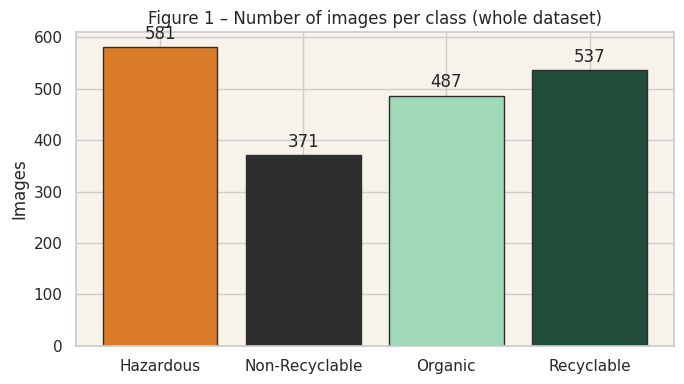

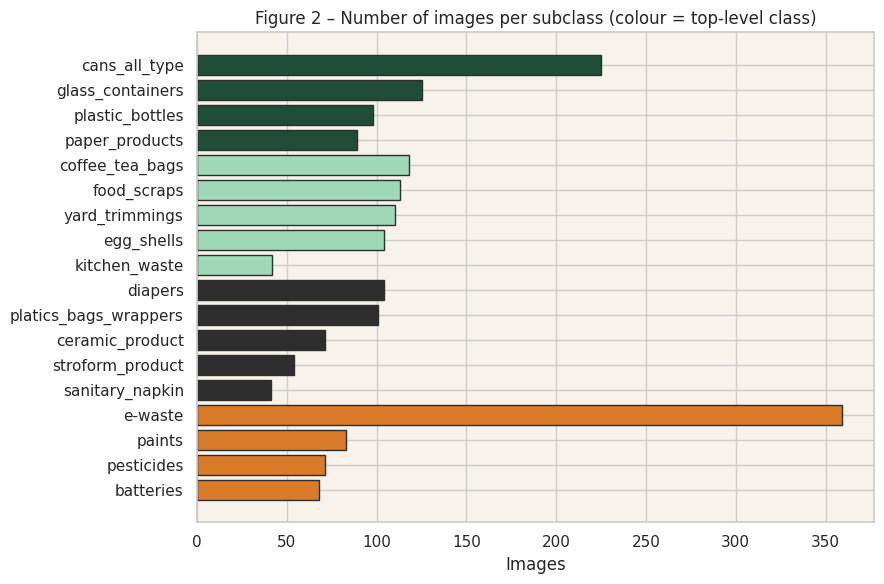

In [6]:
df_meta = pd.DataFrame({"class": raw["class"], "subclass": raw["subclass"]})

CLASS_NAMES = sorted(df_meta["class"].unique().tolist())
label2id = {c: i for i, c in enumerate(CLASS_NAMES)}
id2label = {i: c for c, i in label2id.items()}
NUM_LABELS = len(CLASS_NAMES)
HAZ_ID = label2id["Hazardous"]
print("Classes:", CLASS_NAMES)
print("label2id:", label2id)

class_counts = df_meta["class"].value_counts().reindex(CLASS_NAMES)
print("\nImages per class:\n", class_counts)
print("\nImages per subclass:\n", df_meta.groupby(["class", "subclass"]).size())

# Figure 1: class distribution
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(class_counts.index, class_counts.values, color=CLASS_COLOURS, edgecolor=PALETTE["charcoal"])
ax.bar_label(bars, padding=3)
ax.set_title("Figure 1 – Number of images per class (whole dataset)")
ax.set_ylabel("Images"); ax.set_xlabel("")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig01_class_distribution.png", dpi=200); plt.show()

# Figure 2: subclass distribution
sub_counts = df_meta.groupby(["class", "subclass"]).size().reset_index(name="n").sort_values(["class", "n"])
fig, ax = plt.subplots(figsize=(9, 6))
colour_map = dict(zip(CLASS_NAMES, CLASS_COLOURS))
ax.barh(sub_counts["subclass"], sub_counts["n"], color=[colour_map[c] for c in sub_counts["class"]], edgecolor=PALETTE["charcoal"])
ax.set_title("Figure 2 – Number of images per subclass (colour = top-level class)")
ax.set_xlabel("Images")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig02_subclass_distribution.png", dpi=200); plt.show()

# Save counts for the report
class_counts.to_csv(f"{RESULTS_DIR}/class_counts.csv")
sub_counts.to_csv(f"{RESULTS_DIR}/subclass_counts.csv", index=False)

## 5. Check for corrupted and duplicate images

- A **corrupted** image cannot be opened/converted to RGB. We drop it.
- An **exact duplicate** is detected with an MD5 hash of a small 64×64 grayscale thumbnail (catches identical and re-saved copies). Duplicates are removed **before splitting** so the same photo cannot appear in both train and test (data leakage).

In [7]:
def thumb_hash(img: Image.Image) -> str:
    small = img.convert("L").resize((64, 64), Image.BILINEAR)
    return hashlib.md5(small.tobytes()).hexdigest()

keep_idx, hashes, n_corrupt, n_dup = [], {}, 0, 0
sizes = []
t0 = time.time()
for i in range(len(raw)):
    try:
        img = raw[i]["image"]
        img = img.convert("RGB")
        sizes.append(img.size)
    except Exception as e:
        n_corrupt += 1
        continue
    h = thumb_hash(img)
    if h in hashes:
        n_dup += 1
        continue
    hashes[h] = i
    keep_idx.append(i)

print(f"Checked {len(raw)} images in {time.time()-t0:.0f}s")
print(f"Corrupted images removed: {n_corrupt}")
print(f"Exact duplicates removed: {n_dup}")
print(f"Images kept: {len(keep_idx)}")

sizes = np.array(sizes)
print(f"Image width  – min {sizes[:,0].min()}, median {int(np.median(sizes[:,0]))}, max {sizes[:,0].max()}")
print(f"Image height – min {sizes[:,1].min()}, median {int(np.median(sizes[:,1]))}, max {sizes[:,1].max()}")

ds = raw.select(keep_idx)
df_meta = pd.DataFrame({"class": ds["class"], "subclass": ds["subclass"]})
json.dump({"total_raw": len(raw), "corrupted": n_corrupt, "duplicates": n_dup, "kept": len(keep_idx)},
          open(f"{RESULTS_DIR}/data_cleaning.json", "w"), indent=2)

Checked 1976 images in 87s
Corrupted images removed: 0
Exact duplicates removed: 188
Images kept: 1788
Image width  – min 230, median 1024, max 7800
Image height – min 167, median 739, max 6008


## 6. Create reproducible train / validation / test splits

70% train, 15% validation, 15% test, **stratified by subclass** so every subclass (e.g. `batteries`, `pesticides`) is present in every split in the same proportion. Fixed seed = 42. The test set is used **only once**, at the end, for final evaluation.

In [8]:
labels_all = np.array([label2id[c] for c in ds["class"]])
sub_all = np.array(ds["subclass"])
idx_all = np.arange(len(ds))


strat_key = sub_all.copy()
vc = pd.Series(strat_key).value_counts()
rare = vc[vc < 7].index.tolist()
if rare:
    print("Rare subclasses (stratifying by class instead for these):", rare)
    for r in rare:
        strat_key[strat_key == r] = "RARE_" + np.array(ds["class"])[strat_key == r]

train_idx, temp_idx = train_test_split(idx_all, test_size=0.30, random_state=SEED, stratify=strat_key)
val_idx, test_idx = train_test_split(temp_idx, test_size=0.50, random_state=SEED, stratify=strat_key[temp_idx])

assert len(set(train_idx) & set(val_idx)) == 0 and len(set(train_idx) & set(test_idx)) == 0 and len(set(val_idx) & set(test_idx)) == 0

train_ds, val_ds, test_ds = ds.select(train_idx), ds.select(val_idx), ds.select(test_idx)
print(f"Train: {len(train_ds)} | Val: {len(val_ds)} | Test: {len(test_ds)}")

split_table = pd.DataFrame({
    "train": pd.Series(labels_all[train_idx]).map(id2label).value_counts(),
    "val":   pd.Series(labels_all[val_idx]).map(id2label).value_counts(),
    "test":  pd.Series(labels_all[test_idx]).map(id2label).value_counts(),
}).reindex(CLASS_NAMES)
print("\nImages per class in each split:\n", split_table)
split_table.to_csv(f"{RESULTS_DIR}/split_counts.csv")
json.dump({"train": train_idx.tolist(), "val": val_idx.tolist(), "test": test_idx.tolist()},
          open(f"{RESULTS_DIR}/split_indices.json", "w"))

Train: 1251 | Val: 268 | Test: 269

Images per class in each split:
                 train  val  test
Hazardous         282   62    59
Non-Recyclable    260   55    55
Organic           336   71    74
Recyclable        373   80    81


## 7. Display sample images from each class

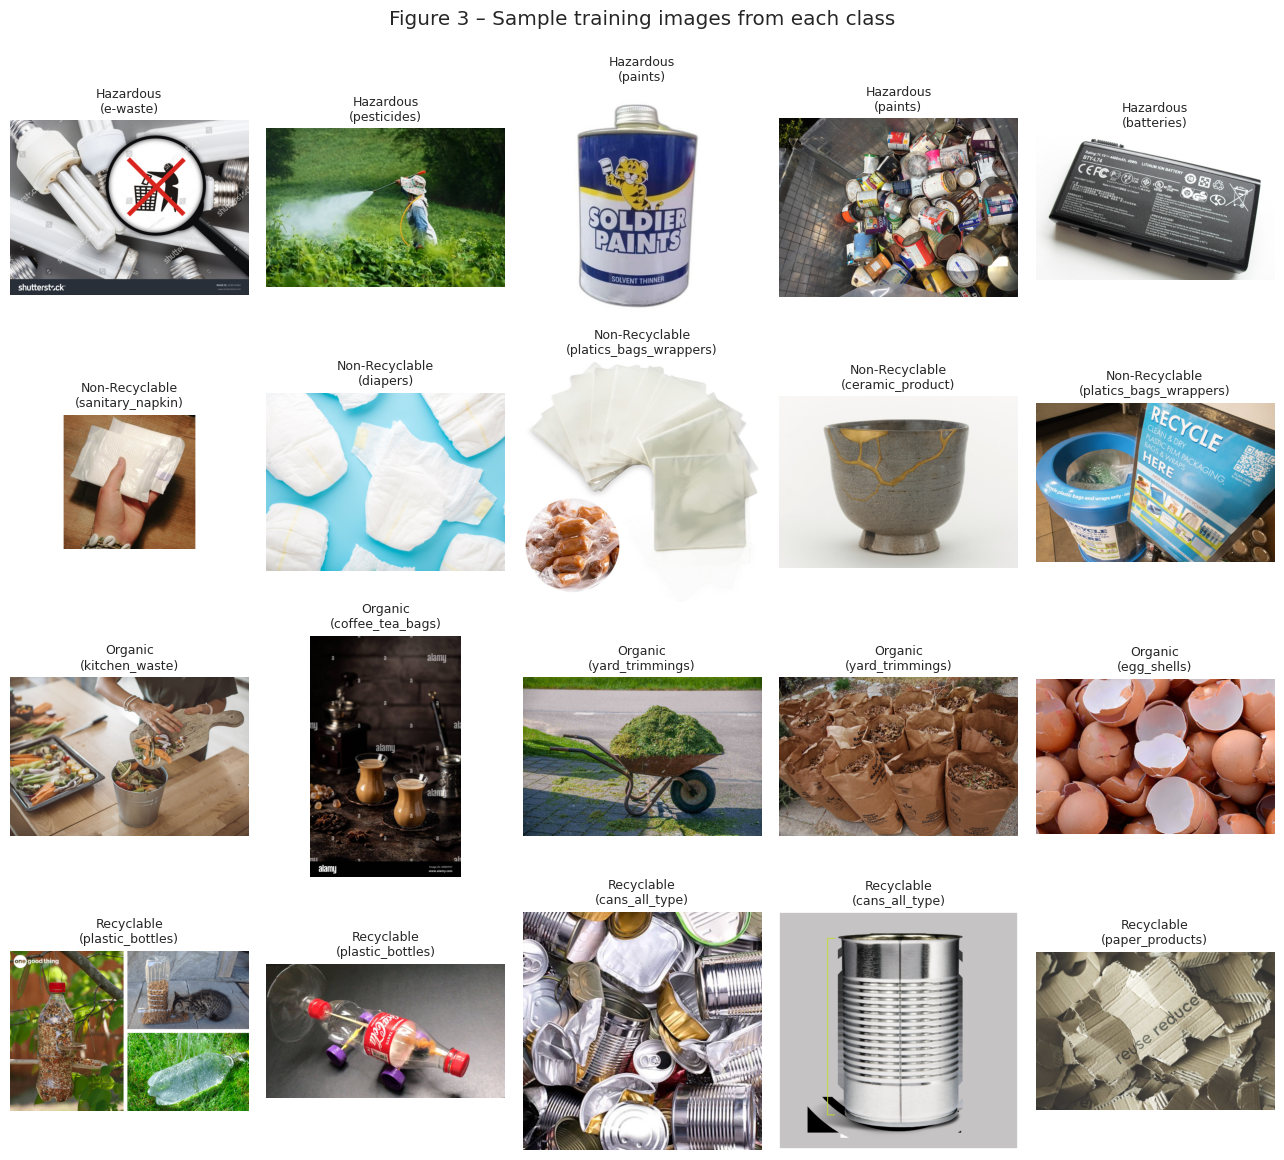

In [9]:
fig, axes = plt.subplots(NUM_LABELS, 5, figsize=(13, 2.9 * NUM_LABELS))
for r, cname in enumerate(CLASS_NAMES):
    cls_idx = [i for i in range(len(train_ds)) if train_ds[i]["class"] == cname][:5]
    for c, i in enumerate(cls_idx):
        ex = train_ds[i]
        axes[r, c].imshow(ex["image"].convert("RGB"))
        axes[r, c].set_title(f"{cname}\n({ex['subclass']})", fontsize=9)
        axes[r, c].axis("off")
plt.suptitle("Figure 3 – Sample training images from each class", y=1.0)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig03_sample_images.png", dpi=200, bbox_inches="tight"); plt.show()

## 8. ViT image processor and preprocessing

The pretrained ViT expects 224×224 RGB images normalised with mean 0.5 and std 0.5 per channel (taken from the processor config, not hard-coded). The image is then cut into 196 patches of 16×16 pixels inside the model.

In [10]:
MODEL_ID = "google/vit-base-patch16-224"
processor = ViTImageProcessor.from_pretrained(MODEL_ID)

_sz = processor.size
IMG_SIZE = int(_sz["height"] if isinstance(_sz, dict) else getattr(_sz, "height", None) or _sz)
MEAN, STD = list(processor.image_mean), list(processor.image_std)
print("Input size:", IMG_SIZE, "| mean:", MEAN, "| std:", STD)

preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

Input size: 224 | mean: [0.5, 0.5, 0.5] | std: [0.5, 0.5, 0.5]


## 9. Data augmentation (training data only)

Training images get mild random crop, horizontal flip and small colour jitter so the model sees more variety and overfits less. Validation and test images are only resized and normalised — **no augmentation**, so the evaluation is fair.

In [11]:
train_tf = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0), ratio=(0.9, 1.1)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.10),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
eval_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

class WasteDataset(Dataset):


    def __init__(self, hf_ds, tf, extra_tf=None):
        self.ds, self.tf, self.extra_tf = hf_ds, tf, extra_tf
    def __len__(self): return len(self.ds)
    def __getitem__(self, i):
        ex = self.ds[i]
        img = ex["image"].convert("RGB")
        if self.extra_tf is not None:
            img = self.extra_tf(img)
        return {"pixel_values": self.tf(img), "labels": label2id[ex["class"]]}

def collate_fn(batch):
    return {"pixel_values": torch.stack([b["pixel_values"] for b in batch]),
            "labels": torch.tensor([b["labels"] for b in batch])}

train_torch = WasteDataset(train_ds, train_tf)
val_torch   = WasteDataset(val_ds, eval_tf)
test_torch  = WasteDataset(test_ds, eval_tf)
sample = train_torch[0]
print("pixel_values shape:", tuple(sample["pixel_values"].shape), "| label:", sample["labels"], id2label[sample["labels"]])

pixel_values shape: (3, 224, 224) | label: 3 Recyclable


## 10. Load the pretrained ViT with a new 4-class head

In [12]:
model = ViTForImageClassification.from_pretrained(
    MODEL_ID,
    num_labels=NUM_LABELS,
    id2label=id2label,
    label2id=label2id,
    ignore_mismatched_sizes=True,
)
n_params = sum(p.numel() for p in model.parameters())
print(f"Parameters: {n_params/1e6:.1f} M")
print("Patch size:", model.config.patch_size, "| hidden size:", model.config.hidden_size,
      "| layers:", model.config.num_hidden_layers, "| attention heads:", model.config.num_attention_heads)

# ---- Training hyper-parameters (reduce BATCH_SIZE / NUM_EPOCHS if Colab runs out of memory or time) ----
BATCH_SIZE = 32
NUM_EPOCHS = 5
LEARNING_RATE = 5e-5

config.json:   0%|          | 0.00/69.7k [00:00<?, ?B/s]

[transformers] You passed `num_labels=4` which is incompatible to the `id2label` map of length `1000`.


model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224
Key               | Status   |                                                                                          
------------------+----------+------------------------------------------------------------------------------------------
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 768]) vs model:torch.Size([4, 768])
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([4])          

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


Parameters: 85.8 M
Patch size: 16 | hidden size: 768 | layers: 12 | attention heads: 12


## 11. Fine-tune the model

In [13]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = logits.argmax(-1)
    acc = accuracy_score(labels, preds)
    p, r, f1, _ = precision_recall_fscore_support(labels, preds, average="macro", zero_division=0)
    haz_recall = ((preds == HAZ_ID) & (labels == HAZ_ID)).sum() / max((labels == HAZ_ID).sum(), 1)
    return {"accuracy": acc, "macro_precision": p, "macro_recall": r, "macro_f1": f1, "hazardous_recall": haz_recall}

# 10 % warm-up, computed in steps so it works on every transformers version
steps_per_epoch = int(np.ceil(len(train_torch) / BATCH_SIZE))
WARMUP_STEPS = int(0.1 * steps_per_epoch * NUM_EPOCHS)

args_kwargs = dict(
    output_dir="checkpoints",
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=BATCH_SIZE,
    num_train_epochs=NUM_EPOCHS,
    learning_rate=LEARNING_RATE,
    weight_decay=0.01,
    warmup_steps=WARMUP_STEPS,
    lr_scheduler_type="cosine",
    logging_strategy="epoch",
    eval_strategy="epoch",          # called `evaluation_strategy` in transformers < 4.41
    save_strategy="epoch",
    save_total_limit=1,
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,
    fp16=(DEVICE == "cuda"),
    dataloader_num_workers=2,
    remove_unused_columns=False,
    report_to="none",
    seed=SEED,
)
# Keep only the arguments this transformers version knows (names changed between 4.x and 5.x)
import inspect
_accepted = set(inspect.signature(TrainingArguments.__init__).parameters)
if "eval_strategy" not in _accepted and "evaluation_strategy" in _accepted:
    args_kwargs["evaluation_strategy"] = args_kwargs.pop("eval_strategy")
_dropped = [k for k in args_kwargs if k not in _accepted]
for k in _dropped:
    args_kwargs.pop(k)
if _dropped:
    print("Note: arguments not supported by this transformers version were dropped:", _dropped)
training_args = TrainingArguments(**args_kwargs)
print(f"Warm-up steps: {WARMUP_STEPS} | steps per epoch: {steps_per_epoch}")

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_torch,
    eval_dataset=val_torch,
    data_collator=collate_fn,
    compute_metrics=compute_metrics,
)

t0 = time.time()
train_result = trainer.train()
train_minutes = (time.time() - t0) / 60
print(f"\nTraining finished in {train_minutes:.1f} minutes")
print(train_result.metrics)

Warm-up steps: 20 | steps per epoch: 40


Epoch,Training Loss,Validation Loss,Accuracy,Macro Precision,Macro Recall,Macro F1,Hazardous Recall
1,1.046884,0.546038,0.843284,0.849602,0.834296,0.839374,0.790323
2,0.256315,0.314802,0.899254,0.898704,0.893602,0.895676,0.870968
3,0.066642,0.257760,0.917910,0.915708,0.915188,0.915181,0.887097
4,0.021824,0.273358,0.902985,0.904941,0.897125,0.899404,0.838710
5,0.016593,0.272645,0.902985,0.904941,0.897125,0.899404,0.838710


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['vit.layers.0.attention.q_proj.weight', 'vit.layers.0.attention.q_proj.bias', 'vit.layers.0.attention.k_proj.weight', 'vit.layers.0.attention.k_proj.bias', 'vit.layers.0.attention.v_proj.weight', 'vit.layers.0.attention.v_proj.bias', 'vit.layers.0.attention.o_proj.weight', 'vit.layers.0.attention.o_proj.bias', 'vit.layers.0.layernorm_before.weight', 'vit.layers.0.layernorm_before.bias', 'vit.layers.0.layernorm_after.weight', 'vit.layers.0.layernorm_after.bias', 'vit.layers.0.mlp.fc1.weight', 'vit.layers.0.mlp.fc1.bias', 'vit.layers.0.mlp.fc2.weight', 'vit.layers.0.mlp.fc2.bias', 'vit.layers.1.attention.q_proj.weight', 'vit.layers.1.attention.q_proj.bias', 'vit.layers.1.attention.k_proj.weight', 'vit.layers.1.attention.k_proj.bias', 'vit.layers.1.attention.v_proj.weight', 'vit.layers.1.attention.v_proj.bias', 'vit.layers.1.attention.o_proj.weight', 'vit.layers.1.attention.o_proj.bias', 'vit.layers.1.layernorm_before


Training finished in 5.2 minutes
{'train_runtime': 311.2339, 'train_samples_per_second': 20.097, 'train_steps_per_second': 0.643, 'total_flos': 4.847210836870349e+17, 'train_loss': 0.2816516238451004, 'epoch': 5.0}


### Training and validation curves

 epoch  eval_loss  eval_accuracy  eval_macro_f1  eval_hazardous_recall
   1.0   0.546038       0.843284       0.839374               0.790323
   2.0   0.314802       0.899254       0.895676               0.870968
   3.0   0.257760       0.917910       0.915181               0.887097
   4.0   0.273358       0.902985       0.899404               0.838710
   5.0   0.272645       0.902985       0.899404               0.838710


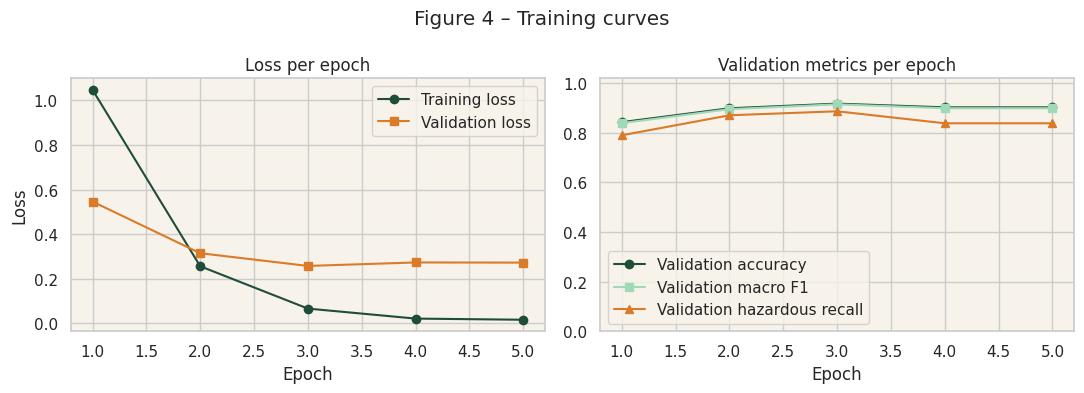

In [14]:
hist = pd.DataFrame(trainer.state.log_history)
train_loss = hist[hist["loss"].notna()][["epoch", "loss"]] if "loss" in hist else pd.DataFrame()
val_rows = hist[hist["eval_loss"].notna()][["epoch", "eval_loss", "eval_accuracy", "eval_macro_f1", "eval_hazardous_recall"]]
print(val_rows.to_string(index=False))
val_rows.to_csv(f"{RESULTS_DIR}/validation_per_epoch.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
if len(train_loss):
    axes[0].plot(train_loss["epoch"], train_loss["loss"], "o-", color=PALETTE["forest"], label="Training loss")
axes[0].plot(val_rows["epoch"], val_rows["eval_loss"], "s-", color=PALETTE["orange"], label="Validation loss")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss"); axes[0].legend(); axes[0].set_title("Loss per epoch")
axes[1].plot(val_rows["epoch"], val_rows["eval_accuracy"], "o-", color=PALETTE["forest"], label="Validation accuracy")
axes[1].plot(val_rows["epoch"], val_rows["eval_macro_f1"], "s-", color=PALETTE["mint"], label="Validation macro F1")
axes[1].plot(val_rows["epoch"], val_rows["eval_hazardous_recall"], "^-", color=PALETTE["orange"], label="Validation hazardous recall")
axes[1].set_xlabel("Epoch"); axes[1].set_ylim(0, 1.02); axes[1].legend(); axes[1].set_title("Validation metrics per epoch")
plt.suptitle("Figure 4 – Training curves")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig04_training_curves.png", dpi=200); plt.show()

## 12. Save the fine-tuned model and label mappings

In [15]:
trainer.save_model(MODEL_DIR)
processor.save_pretrained(MODEL_DIR)
json.dump({"id2label": id2label, "label2id": label2id, "class_names": CLASS_NAMES}, open(f"{MODEL_DIR}/labels.json", "w"), indent=2)
print("Saved to", MODEL_DIR, "->", os.listdir(MODEL_DIR))

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved to saved_model -> ['model.safetensors', 'labels.json', 'training_args.bin', 'config.json', 'preprocessor_config.json']


## 13. Final evaluation on the held-out test set

The test set has never been seen during training or model selection. We report accuracy, macro precision/recall/F1, per-class metrics, the confusion matrix, and the two hazardous-specific numbers:

- **Hazardous recall** = of all truly hazardous items, how many did the model catch?
- **Hazardous false-negative rate** = 1 − recall = how many hazardous items were wrongly sent to a non-hazardous bin. This is the dangerous error in waste sorting.

In [16]:
def predict_dataset(torch_ds, batch_size=64):
    # Return (predictions, true labels, softmax confidences) for a WasteDataset.
    model.eval()
    loader = DataLoader(torch_ds, batch_size=batch_size, shuffle=False, collate_fn=collate_fn, num_workers=2)
    all_logits, all_labels = [], []
    with torch.no_grad():
        for batch in loader:
            out = model(pixel_values=batch["pixel_values"].to(model.device))
            all_logits.append(out.logits.float().cpu()); all_labels.append(batch["labels"])
    logits = torch.cat(all_logits); labels = torch.cat(all_labels).numpy()
    probs = torch.softmax(logits, dim=-1).numpy()
    return probs.argmax(-1), labels, probs

def summarise(preds, labels, name):
    acc = accuracy_score(labels, preds)
    p, r, f1, _ = precision_recall_fscore_support(labels, preds, average="macro", zero_division=0)
    haz_mask = labels == HAZ_ID
    haz_recall = (preds[haz_mask] == HAZ_ID).mean() if haz_mask.sum() else float("nan")
    haz_fn = int(((labels == HAZ_ID) & (preds != HAZ_ID)).sum())
    haz_fp = int(((labels != HAZ_ID) & (preds == HAZ_ID)).sum())
    return {"condition": name, "accuracy": acc, "macro_precision": p, "macro_recall": r, "macro_f1": f1,
            "hazardous_recall": haz_recall, "hazardous_fn_rate": 1 - haz_recall,
            "hazardous_false_negatives": haz_fn, "hazardous_false_positives": haz_fp, "n_hazardous": int(haz_mask.sum())}

test_preds, test_labels, test_probs = predict_dataset(test_torch)
baseline = summarise(test_preds, test_labels, "Original")
print("=== TEST SET (original images) ===")
for k, v in baseline.items():
    print(f"{k:28s}: {v:.4f}" if isinstance(v, float) else f"{k:28s}: {v}")

print("\nPer-class report:")
report_txt = classification_report(test_labels, test_preds, target_names=CLASS_NAMES, digits=4, zero_division=0)
print(report_txt)
report_dict = classification_report(test_labels, test_preds, target_names=CLASS_NAMES, output_dict=True, zero_division=0)
pd.DataFrame(report_dict).T.to_csv(f"{RESULTS_DIR}/test_classification_report.csv")
json.dump(baseline, open(f"{RESULTS_DIR}/test_metrics_original.json", "w"), indent=2)

=== TEST SET (original images) ===
condition                   : Original
accuracy                    : 0.9257
macro_precision             : 0.9285
macro_recall                : 0.9217
macro_f1                    : 0.9246
hazardous_recall            : 0.8983
hazardous_fn_rate           : 0.1017
hazardous_false_negatives   : 6
hazardous_false_positives   : 2
n_hazardous                 : 59

Per-class report:
                precision    recall  f1-score   support

     Hazardous     0.9636    0.8983    0.9298        59
Non-Recyclable     0.9245    0.8909    0.9074        55
       Organic     0.9103    0.9595    0.9342        74
    Recyclable     0.9157    0.9383    0.9268        81

      accuracy                         0.9257       269
     macro avg     0.9285    0.9217    0.9246       269
  weighted avg     0.9265    0.9257    0.9255       269



### Confusion matrix

                     Pred Hazardous  Pred Non-Recyclable  Pred Organic  \
True Hazardous                   53                    0             3   
True Non-Recyclable               0                   49             2   
True Organic                      0                    3            71   
True Recyclable                   2                    1             2   

                     Pred Recyclable  
True Hazardous                     3  
True Non-Recyclable                4  
True Organic                       0  
True Recyclable                   76  


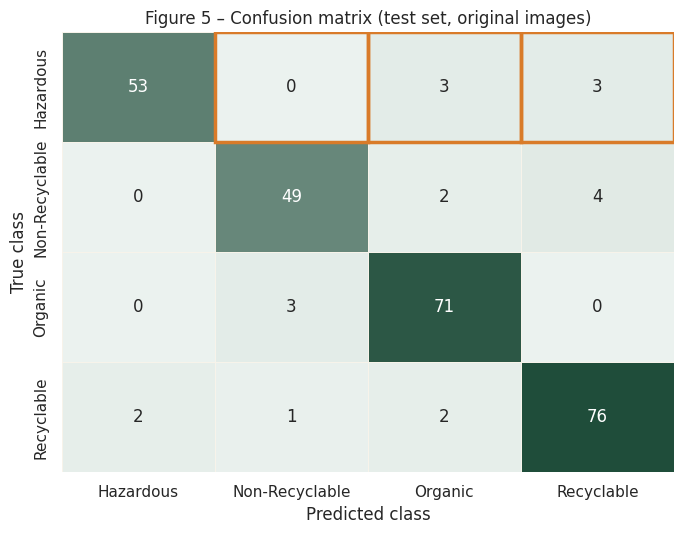

In [17]:
cm = confusion_matrix(test_labels, test_preds, labels=list(range(NUM_LABELS)))
cm_df = pd.DataFrame(cm, index=[f"True {c}" for c in CLASS_NAMES], columns=[f"Pred {c}" for c in CLASS_NAMES])
print(cm_df)
cm_df.to_csv(f"{RESULTS_DIR}/confusion_matrix.csv")

fig, ax = plt.subplots(figsize=(7, 5.5))
cmap = sns.light_palette(PALETTE["forest"], as_cmap=True)
sns.heatmap(cm, annot=True, fmt="d", cmap=cmap, cbar=False, xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax,
            linewidths=0.5, linecolor=PALETTE["cream"], annot_kws={"size": 12})
ax.set_xlabel("Predicted class"); ax.set_ylabel("True class"); ax.set_title("Figure 5 – Confusion matrix (test set, original images)")
# highlight the hazardous row's off-diagonal cells (false negatives) in orange
for j in range(NUM_LABELS):
    if j != HAZ_ID:
        ax.add_patch(plt.Rectangle((j, HAZ_ID), 1, 1, fill=False, edgecolor=PALETTE["orange"], lw=2.5))
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig05_confusion_matrix.png", dpi=200); plt.show()

## 14. Hazardous-waste error analysis

Two questions: (1) **Which hazardous subclasses are missed** (e.g. are pesticide bottles confused with plastic bottles?), and (2) **where do the missed items go** (which non-hazardous bin would they wrongly end up in)?

Hazardous test images: 59 | correctly detected: 53 | missed (false negatives): 6

Recall per hazardous subclass:
            detected  total    recall
subclass                             
batteries         10     10  1.000000
e-waste           24     27  0.888889
paints             9     12  0.750000
pesticides        10     10  1.000000

Where do missed hazardous items go? (true subclass -> wrongly predicted class)
  subclass        pred  count
0  e-waste     Organic      2
1  e-waste  Recyclable      1
2   paints     Organic      1
3   paints  Recyclable      2

Non-hazardous items wrongly predicted as Hazardous (false positives):
         true          subclass  count
0  Recyclable     cans_all_type      1
1  Recyclable  glass_containers      1


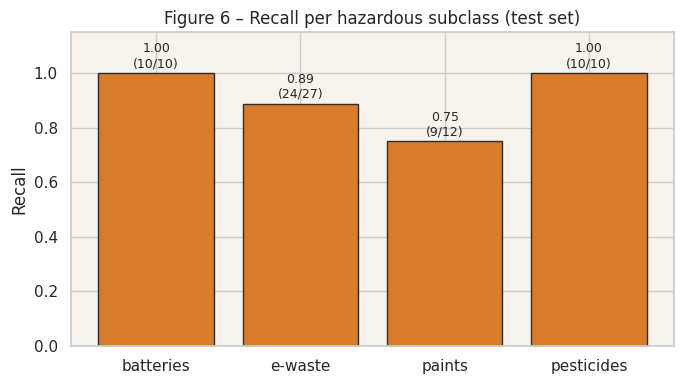

In [18]:
test_sub = np.array(test_ds["subclass"])
test_df = pd.DataFrame({"true": [id2label[i] for i in test_labels], "pred": [id2label[i] for i in test_preds],
                        "subclass": test_sub, "confidence": test_probs.max(-1), "idx": np.arange(len(test_labels))})
test_df["correct"] = test_df["true"] == test_df["pred"]
test_df.to_csv(f"{RESULTS_DIR}/test_predictions.csv", index=False)

haz = test_df[test_df["true"] == "Hazardous"]
print(f"Hazardous test images: {len(haz)} | correctly detected: {haz['correct'].sum()} | missed (false negatives): {(~haz['correct']).sum()}")

print("\nRecall per hazardous subclass:")
haz_sub = haz.groupby("subclass")["correct"].agg(["sum", "count"]).rename(columns={"sum": "detected", "count": "total"})
haz_sub["recall"] = haz_sub["detected"] / haz_sub["total"]
print(haz_sub)
haz_sub.to_csv(f"{RESULTS_DIR}/hazardous_subclass_recall.csv")

print("\nWhere do missed hazardous items go? (true subclass -> wrongly predicted class)")
fn_table = haz[~haz["correct"]].groupby(["subclass", "pred"]).size().reset_index(name="count")
print(fn_table if len(fn_table) else "No hazardous false negatives on the test set.")
fn_table.to_csv(f"{RESULTS_DIR}/hazardous_false_negatives.csv", index=False)

print("\nNon-hazardous items wrongly predicted as Hazardous (false positives):")
fp_table = test_df[(test_df["true"] != "Hazardous") & (test_df["pred"] == "Hazardous")].groupby(["true", "subclass"]).size().reset_index(name="count")
print(fp_table if len(fp_table) else "None.")

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(haz_sub.index, haz_sub["recall"], color=PALETTE["orange"], edgecolor=PALETTE["charcoal"])
ax.bar_label(bars, labels=[f"{v:.2f}\n({d}/{t})" for v, d, t in zip(haz_sub['recall'], haz_sub['detected'], haz_sub['total'])], padding=2, fontsize=9)
ax.set_ylim(0, 1.15); ax.set_ylabel("Recall"); ax.set_title("Figure 6 – Recall per hazardous subclass (test set)")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig06_hazardous_subclass_recall.png", dpi=200); plt.show()

## 15. Controlled image-quality experiment

Real bins and phone cameras do not produce clean product photos. We apply three realistic degradations to the **same test images** (no retraining, no new data) and measure the drop:

| Condition | Setting | Simulates |
|---|---|---|
| Blur | Gaussian blur, radius 2 px (applied at original resolution) | out-of-focus / moving camera |
| Dark | brightness × 0.5 | poor lighting inside a bin |
| JPEG | re-encode at quality 20 | heavy compression (e.g. messaging apps) |

Limitation: these are simple synthetic transformations. They approximate, but do not equal, real-world conditions such as dirt, occlusion or mixed items.

             accuracy  macro_f1  hazardous_recall  hazardous_false_negatives  \
condition                                                                      
Original       0.9257    0.9246            0.8983                          6   
Blur (r=2)     0.9145    0.9137            0.8983                          6   
Dark (x0.5)    0.9033    0.9026            0.9153                          5   
JPEG (q=20)    0.9182    0.9169            0.8814                          7   

             hazardous_false_positives  
condition                               
Original                             2  
Blur (r=2)                           6  
Dark (x0.5)                          6  
JPEG (q=20)                          2  


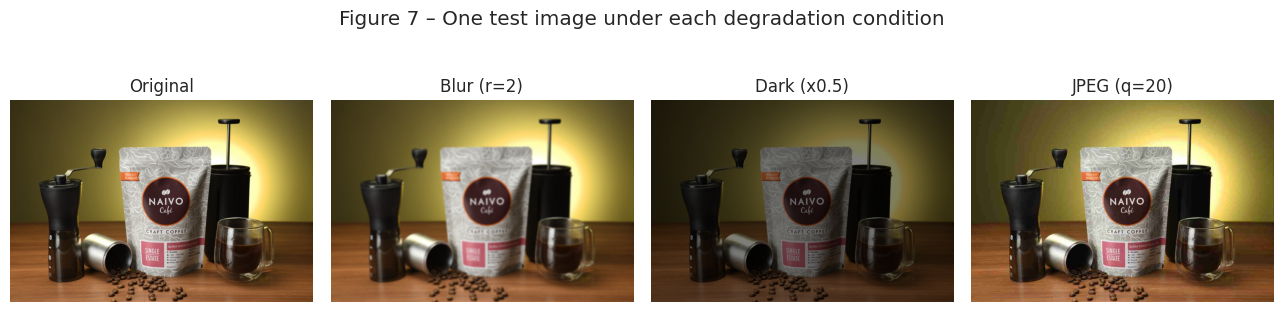

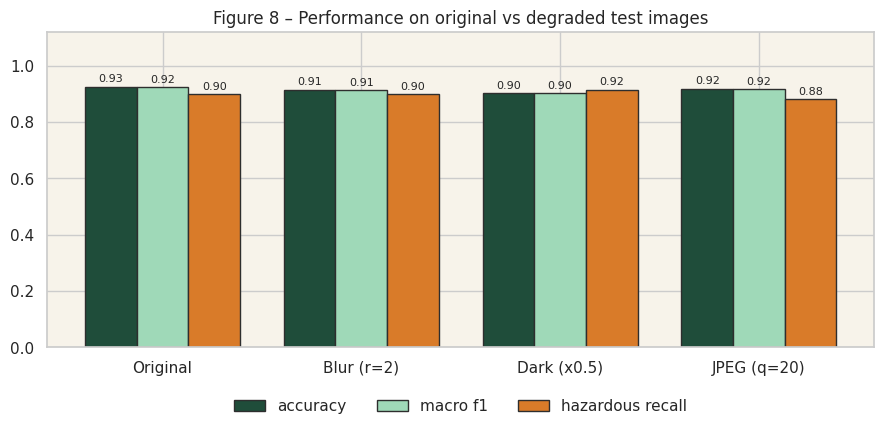

In [19]:
def blur_tf(img):   return img.filter(ImageFilter.GaussianBlur(radius=2))
def dark_tf(img):   return ImageEnhance.Brightness(img).enhance(0.5)
def jpeg_tf(img, quality=20):
    buf = io.BytesIO(); img.save(buf, format="JPEG", quality=quality); buf.seek(0)
    return Image.open(buf).convert("RGB")

conditions = {"Original": None, "Blur (r=2)": blur_tf, "Dark (x0.5)": dark_tf, "JPEG (q=20)": jpeg_tf}
rows, cond_preds = [], {}
for name, fn in conditions.items():
    if fn is None:
        preds = test_preds
    else:
        preds, _, _ = predict_dataset(WasteDataset(test_ds, eval_tf, extra_tf=fn))
    cond_preds[name] = preds
    rows.append(summarise(preds, test_labels, name))

robust_df = pd.DataFrame(rows).set_index("condition")
print(robust_df[["accuracy", "macro_f1", "hazardous_recall", "hazardous_false_negatives", "hazardous_false_positives"]].round(4))
robust_df.to_csv(f"{RESULTS_DIR}/robustness_results.csv")

# Show one example image under each condition
ex_img = test_ds[0]["image"].convert("RGB")
fig, axes = plt.subplots(1, 4, figsize=(13, 3.6))
for ax, (name, fn) in zip(axes, conditions.items()):
    ax.imshow(ex_img if fn is None else fn(ex_img)); ax.set_title(name); ax.axis("off")
plt.suptitle("Figure 7 – One test image under each degradation condition")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig07_degradation_examples.png", dpi=200); plt.show()

# Grouped bar chart
metrics_to_plot = ["accuracy", "macro_f1", "hazardous_recall"]
x = np.arange(len(robust_df)); w = 0.26
fig, ax = plt.subplots(figsize=(9, 4.5))
for k, (m, col) in enumerate(zip(metrics_to_plot, [PALETTE["forest"], PALETTE["mint"], PALETTE["orange"]])):
    bars = ax.bar(x + (k - 1) * w, robust_df[m], w, label=m.replace("_", " "), color=col, edgecolor=PALETTE["charcoal"])
    ax.bar_label(bars, fmt="%.2f", padding=2, fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(robust_df.index); ax.set_ylim(0, 1.12)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3, frameon=False)
ax.set_title("Figure 8 – Performance on original vs degraded test images")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig08_robustness_comparison.png", dpi=200); plt.show()

## 16. Correctly and incorrectly classified examples

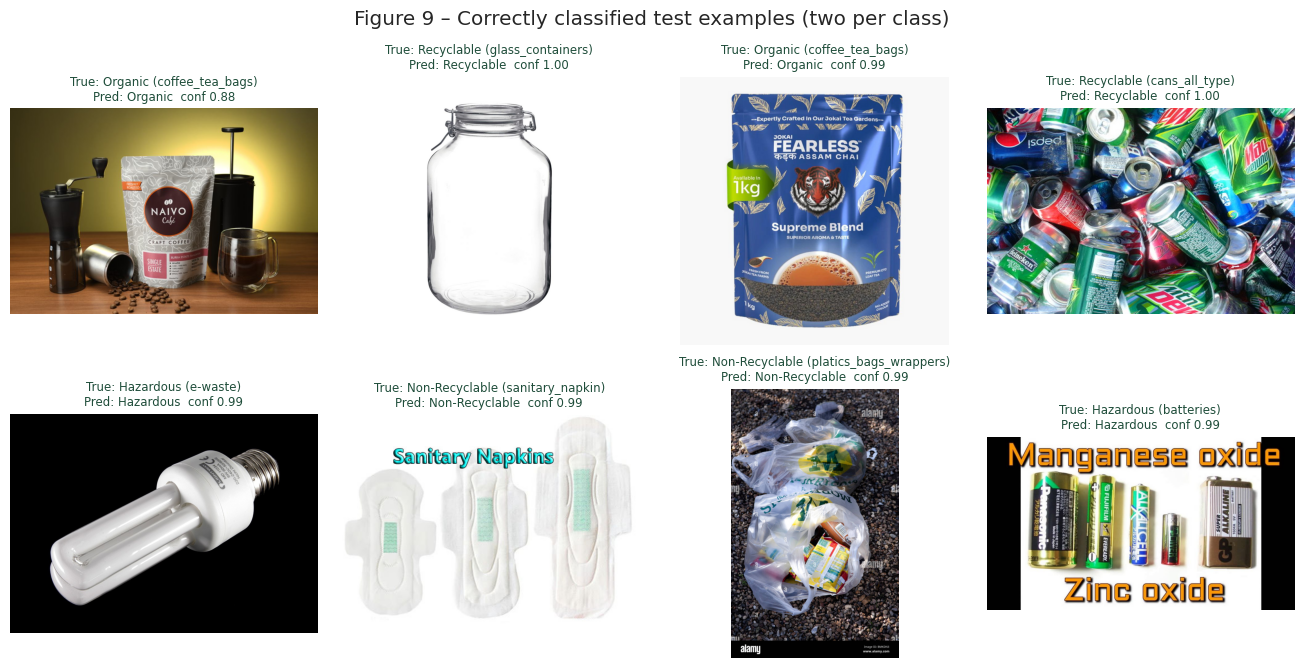

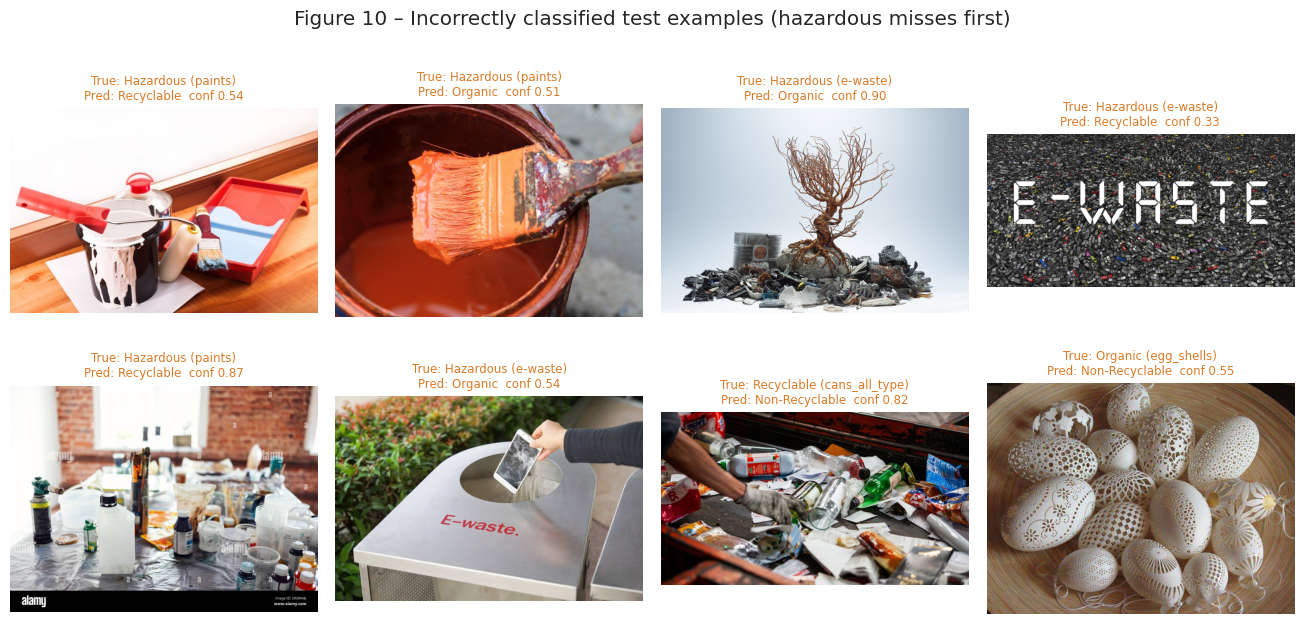

Total errors on test set: 20 of 269


In [20]:
def show_examples(sub_df, title, fname, n=8):
    sub_df = sub_df.head(n)
    if len(sub_df) == 0:
        print(f"No examples for: {title}"); return
    cols = min(4, len(sub_df)); rows_ = int(np.ceil(len(sub_df) / cols))
    fig, axes = plt.subplots(rows_, cols, figsize=(3.3 * cols, 3.4 * rows_)); axes = np.array(axes).reshape(-1)
    for ax, (_, r) in zip(axes, sub_df.iterrows()):
        ax.imshow(test_ds[int(r["idx"])]["image"].convert("RGB")); ax.axis("off")
        colour = PALETTE["forest"] if r["correct"] else PALETTE["orange"]
        ax.set_title(f"True: {r['true']} ({r['subclass']})\nPred: {r['pred']}  conf {r['confidence']:.2f}", fontsize=8.5, color=colour)
    for ax in axes[len(sub_df):]: ax.axis("off")
    plt.suptitle(title); plt.tight_layout(); plt.savefig(f"{FIG_DIR}/{fname}", dpi=200, bbox_inches="tight"); plt.show()

correct_examples = test_df[test_df["correct"]].groupby("true", group_keys=False).head(2)
show_examples(correct_examples, "Figure 9 – Correctly classified test examples (two per class)", "fig09_correct_examples.png")

wrong = test_df[~test_df["correct"]]
# show hazardous misses first – they matter most
wrong = pd.concat([wrong[wrong["true"] == "Hazardous"], wrong[wrong["true"] != "Hazardous"]])
show_examples(wrong, "Figure 10 – Incorrectly classified test examples (hazardous misses first)", "fig10_incorrect_examples.png")
print(f"Total errors on test set: {len(wrong)} of {len(test_df)}")

## 17. Prediction demonstration (single image → class + confidence)

idx 0: true=Organic | pred=Organic | confidence=0.876 | all={'Hazardous': 0.104, 'Non-Recyclable': 0.003, 'Organic': 0.876, 'Recyclable': 0.017}
idx 1: true=Recyclable | pred=Recyclable | confidence=0.997 | all={'Hazardous': 0.001, 'Non-Recyclable': 0.002, 'Organic': 0.0, 'Recyclable': 0.997}
idx 5: true=Hazardous | pred=Hazardous | confidence=0.988 | all={'Hazardous': 0.988, 'Non-Recyclable': 0.003, 'Organic': 0.002, 'Recyclable': 0.007}
idx 18: true=Non-Recyclable | pred=Non-Recyclable | confidence=0.987 | all={'Hazardous': 0.005, 'Non-Recyclable': 0.987, 'Organic': 0.006, 'Recyclable': 0.003}


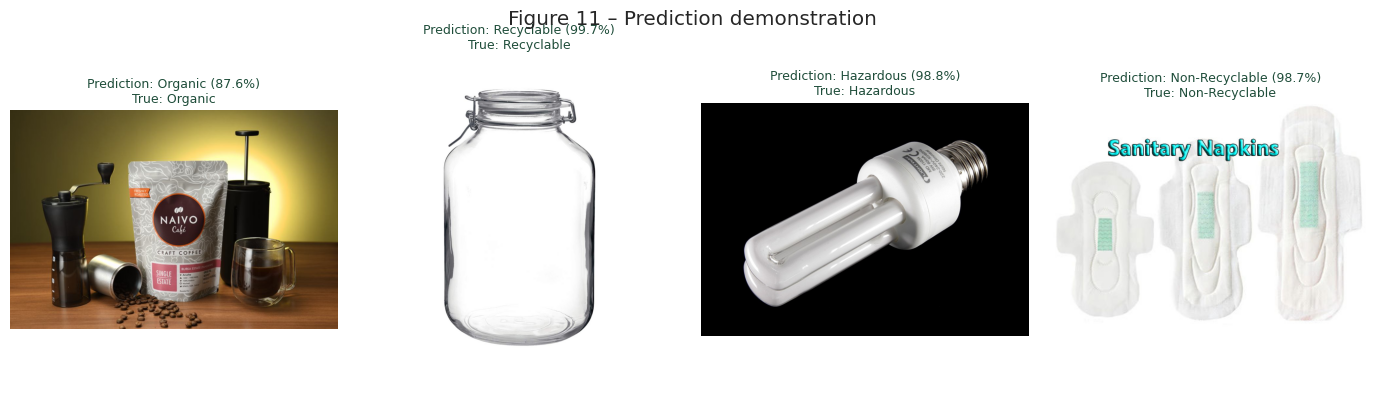

In [21]:
def predict_image(img: Image.Image):
    model.eval()
    x = eval_tf(img.convert("RGB")).unsqueeze(0).to(model.device)
    with torch.no_grad():
        probs = torch.softmax(model(pixel_values=x).logits.float(), -1)[0].cpu().numpy()
    top = int(probs.argmax())
    return id2label[top], float(probs[top]), {id2label[i]: float(p) for i, p in enumerate(probs)}

demo_idx = list(test_df.groupby("true").head(1)["idx"])
fig, axes = plt.subplots(1, len(demo_idx), figsize=(3.5 * len(demo_idx), 4))
for ax, i in zip(np.atleast_1d(axes), demo_idx):
    img = test_ds[int(i)]["image"]
    pred, conf, allp = predict_image(img)
    true = test_ds[int(i)]["class"]
    ax.imshow(img.convert("RGB")); ax.axis("off")
    ax.set_title(f"Prediction: {pred} ({conf:.1%})\nTrue: {true}", fontsize=9,
                 color=PALETTE["forest"] if pred == true else PALETTE["orange"])
    print(f"idx {i}: true={true} | pred={pred} | confidence={conf:.3f} | all={ {k: round(v,3) for k,v in allp.items()} }")
plt.suptitle("Figure 11 – Prediction demonstration")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig11_prediction_demo.png", dpi=200, bbox_inches="tight"); plt.show()


## 18. Save a results summary and download everything

Everything the report and slides need is in `results/` (CSV/JSON + `results/figures/*.png`). The cell below zips it. **Do not commit `saved_model/` to GitHub** (~330 MB).

In [22]:
summary = {
    "dataset": DATASET_ID, "model": MODEL_ID, "seed": SEED,
    "n_raw": len(raw), "n_after_cleaning": len(ds), "corrupted_removed": n_corrupt, "duplicates_removed": n_dup,
    "n_train": len(train_ds), "n_val": len(val_ds), "n_test": len(test_ds),
    "classes": CLASS_NAMES, "class_counts": class_counts.to_dict(),
    "hyperparameters": {"batch_size": BATCH_SIZE, "epochs": NUM_EPOCHS, "learning_rate": LEARNING_RATE,
                        "weight_decay": 0.01, "warmup_steps": WARMUP_STEPS, "scheduler": "cosine", "fp16": DEVICE == "cuda"},
    "training_minutes": round(train_minutes, 1),
    "best_validation_macro_f1": float(val_rows["eval_macro_f1"].max()),
    "test_original": baseline,
    "robustness": {k: {m: float(v) for m, v in r.items() if m != "condition"} for k, r in robust_df.to_dict("index").items()},
    "hazardous_subclass_recall": haz_sub["recall"].round(4).to_dict(),
    "transformers_version": transformers.__version__, "torch_version": torch.__version__,
    "gpu": torch.cuda.get_device_name(0) if DEVICE == "cuda" else "cpu",
}
json.dump(summary, open(f"{RESULTS_DIR}/summary.json", "w"), indent=2, default=float)
print(json.dumps(summary, indent=2, default=float))

!zip -qr results.zip results
print("\nCreated results.zip – download it from the Files panel (left sidebar) or run the next cell.")

{
  "dataset": "huaweilin/waste-classification",
  "model": "google/vit-base-patch16-224",
  "seed": 42,
  "n_raw": 1976,
  "n_after_cleaning": 1788,
  "corrupted_removed": 0,
  "duplicates_removed": 188,
  "n_train": 1251,
  "n_val": 268,
  "n_test": 269,
  "classes": [
    "Hazardous",
    "Non-Recyclable",
    "Organic",
    "Recyclable"
  ],
  "class_counts": {
    "Hazardous": 581,
    "Non-Recyclable": 371,
    "Organic": 487,
    "Recyclable": 537
  },
  "hyperparameters": {
    "batch_size": 32,
    "epochs": 5,
    "learning_rate": 5e-05,
    "weight_decay": 0.01,
    "warmup_steps": 20,
    "scheduler": "cosine",
    "fp16": true
  },
  "training_minutes": 5.2,
  "best_validation_macro_f1": 0.9151806091298609,
  "test_original": {
    "condition": "Original",
    "accuracy": 0.9256505576208178,
    "macro_precision": 0.928520931595494,
    "macro_recall": 0.9217363100131462,
    "macro_f1": 0.9245679408548472,
    "hazardous_recall": 0.8983050847457628,
    "hazardous_fn_rate

In [23]:
!zip -qr results.zip results
from google.colab import files
files.download("results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Saving tire.png to tire.png


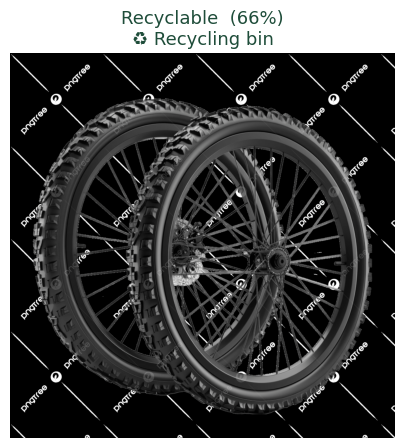

  Recyclable       ███████████████████            66.0%
  Hazardous        ██████                         20.4%
  Organic          ███                            10.3%
  Non-Recyclable   █                              3.3%
  ⚠️ Hazardous probability is not small — human check recommended



In [25]:
# ===== LIVE DEMO: upload any photo → prediction =====
from google.colab import files
from PIL import Image
import matplotlib.pyplot as plt

TIPS = {"Hazardous": "⚠️ Do NOT put in a normal bin — take to a hazardous / e-waste collection point",
        "Recyclable": "♻️ Recycling bin", "Organic": "🌱 Compost / food-waste bin",
        "Non-Recyclable": "🗑️ General waste bin"}

up = files.upload()
for name in up:
    img = Image.open(name).convert("RGB")
    pred, conf, allp = predict_image(img)
    colour = "#D97B29" if pred == "Hazardous" else "#1F4D3A"
    plt.figure(figsize=(5, 5)); plt.imshow(img); plt.axis("off")
    plt.title(f"{pred}  ({conf:.0%})\n{TIPS[pred]}", fontsize=13, color=colour)
    plt.show()
    for k, v in sorted(allp.items(), key=lambda kv: -kv[1]):
        print(f"  {k:16s} {'█' * int(v * 30):30s} {v:.1%}")
    if pred != "Hazardous" and allp["Hazardous"] > 0.2:
        print("  ⚠️ Hazardous probability is not small — human check recommended")
    print()